In [113]:
import pandas as pd

base_vendas = pd.read_excel("base_vendas_ecommerce_etl.xlsx")


In [114]:
base_vendas["nome_cliente"] = base_vendas["nome_cliente"].str.title()
base_vendas["nome_cliente"] = base_vendas["nome_cliente"].str.strip().str.replace(r"\s+", " ", regex=True)


base_vendas

,id_pedido,data_pedido,nome_cliente,produto,categoria,quantidade,preco_unitario,valor_total,metodo_pagamento,estado_cliente,status_pedido
0,ORD-15118,2024-10-30 05:31:00,Gabriel Alves,Livro Data Science Guide,Livros,2.0,90,180.0,Cartão de Crédito,São Paulo,Em Processamento
1,ORD-18931,2024-03-14 15:24:00,Carlos Eduardo Santos,Teclado Mecânico,Acessórios,2.0,350,700.0,CREDITO,RS,Em Processamento
2,ORD-18515,2024-07-19 10:09:00,Maria Oliveira,Cadeira Ergonômica,Móveis,5.0,850,4250.0,Boleto,SP,Em Processamento
3,ORD-17282,2025-03-14 22:58:00,Rodrigo Ferreira,Fone de Ouvido Bluetooth,Acessórios,5.0,200,1000.0,Cartão de Crédito,Bahia,Concluído
4,ORD-17623,2024-10-06 14:30:00,Ana Silva,Aspirador de Pó,Eletrodomésticos,5.0,300,1500.0,Boleto,RS,Cancelado
...,...,...,...,...,...,...,...,...,...,...,...
10495,ORD-15734,2024-08-20 15:04:00,Thiago Carvalho,Cafeteira Expressa,Eletrodomésticos,4.0,400,1600.0,pix,RJ,Cancelado
10496,ORD-15191,2024-09-21 02:28:00,Gabriel Alves,Monitor 27 Polegadas,Eletrônicos,4.0,1200,4800.0,CREDITO,Rio de Janeiro,Pendente
10497,ORD-15390,2024-01-06 15:06:00,Beatriz Costa,Notebook Pro,Eletrônicos,3.0,4500,13500.0,PIX,São Paulo,Pendente
10498,ORD-10860,2025-02-25 17:50:00,Thiago Carvalho,Cadeira Ergonômica,Móveis,5.0,850,4250.0,boleto bancario,Rio de Janeiro,Em Processamento


In [115]:
base_vendas["metodo_pagamento"] = base_vendas["metodo_pagamento"].str.lower()

base_vendas

,id_pedido,data_pedido,nome_cliente,produto,categoria,quantidade,preco_unitario,valor_total,metodo_pagamento,estado_cliente,status_pedido
0,ORD-15118,2024-10-30 05:31:00,Gabriel Alves,Livro Data Science Guide,Livros,2.0,90,180.0,cartão de crédito,São Paulo,Em Processamento
1,ORD-18931,2024-03-14 15:24:00,Carlos Eduardo Santos,Teclado Mecânico,Acessórios,2.0,350,700.0,credito,RS,Em Processamento
2,ORD-18515,2024-07-19 10:09:00,Maria Oliveira,Cadeira Ergonômica,Móveis,5.0,850,4250.0,boleto,SP,Em Processamento
3,ORD-17282,2025-03-14 22:58:00,Rodrigo Ferreira,Fone de Ouvido Bluetooth,Acessórios,5.0,200,1000.0,cartão de crédito,Bahia,Concluído
4,ORD-17623,2024-10-06 14:30:00,Ana Silva,Aspirador de Pó,Eletrodomésticos,5.0,300,1500.0,boleto,RS,Cancelado
...,...,...,...,...,...,...,...,...,...,...,...
10495,ORD-15734,2024-08-20 15:04:00,Thiago Carvalho,Cafeteira Expressa,Eletrodomésticos,4.0,400,1600.0,pix,RJ,Cancelado
10496,ORD-15191,2024-09-21 02:28:00,Gabriel Alves,Monitor 27 Polegadas,Eletrônicos,4.0,1200,4800.0,credito,Rio de Janeiro,Pendente
10497,ORD-15390,2024-01-06 15:06:00,Beatriz Costa,Notebook Pro,Eletrônicos,3.0,4500,13500.0,pix,São Paulo,Pendente
10498,ORD-10860,2025-02-25 17:50:00,Thiago Carvalho,Cadeira Ergonômica,Móveis,5.0,850,4250.0,boleto bancario,Rio de Janeiro,Em Processamento


In [116]:
import seaborn as sns
import matplotlib.pyplot as plt

In [117]:
def limpar_metodo_pagamento(pagamento):
    credito = ["cartao de credito", "cartão de crédito", "credito"]
    debito = ["cartão de débito", "debito"]
    boleto = ["boleto", "boleto bancario"]
    
    
    if not isinstance(pagamento, str):
        return "Não informado"
    
    if any(metodo in pagamento for metodo in debito):
        return "Débito"
    elif any(metodo in pagamento for metodo in credito):
        return "Crédito"
    elif any(metodo in pagamento for metodo in boleto):
        return "Boleto bancário"
    elif "pix" in pagamento:
        return "Pix"
    else:
        return pagamento
    
    
base_vendas["metodo_pagamento"] = base_vendas["metodo_pagamento"].apply(limpar_metodo_pagamento)
base_vendas.groupby("metodo_pagamento").count()

,id_pedido,data_pedido,nome_cliente,produto,categoria,quantidade,preco_unitario,valor_total,estado_cliente,status_pedido
metodo_pagamento,,,,,,,,,,
Boleto bancário,2019,2019,2019,2019,2019,1958,2019,1888,1956,2019
Crédito,3055,3055,3055,3055,3055,2979,3055,2892,2967,3055
Débito,2040,2040,2040,2040,2040,1963,2040,1904,1979,2040
Não informado,421,421,421,421,421,406,421,398,407,421
Pix,2965,2965,2965,2965,2965,2873,2965,2771,2874,2965


In [118]:
base_vendas.groupby('estado_cliente').count()

,id_pedido,data_pedido,nome_cliente,produto,categoria,quantidade,preco_unitario,valor_total,metodo_pagamento,status_pedido
estado_cliente,,,,,,,,,,
BA,810,810,810,810,810,791,810,768,810,810
Bahia,840,840,840,840,840,819,840,789,840,840
MG,757,757,757,757,757,735,757,709,757,757
Minas Gerais,793,793,793,793,793,766,793,746,793,793
PR,805,805,805,805,805,774,805,747,805,805
Paraná,821,821,821,821,821,796,821,776,821,821
RJ,784,784,784,784,784,753,784,730,784,784
RS,730,730,730,730,730,707,730,678,730,730
Rio de Janeiro,761,761,761,761,761,744,761,719,761,761


In [119]:
estados = {
    "Ceará" : "CE",
    "Minas Gerais" : "MG",
    "Bahia" : "BA",
    "Paraná" : "PR",
    "Rio de Janeiro" : "RJ",
    "Santa Catarina" : "SC",
    "Rio Grande do Sul" : "RS",
    "": "Não informado",
    "São Paulo": "SP"
}


base_vendas["estado_cliente"] = base_vendas["estado_cliente"].fillna("Não informado")
base_vendas["estado_cliente"] = base_vendas["estado_cliente"].replace(estados)
base_vendas["estado_cliente"] = base_vendas["estado_cliente"].str.upper()


base_vendas.groupby('estado_cliente').count()

,id_pedido,data_pedido,nome_cliente,produto,categoria,quantidade,preco_unitario,valor_total,metodo_pagamento,status_pedido
estado_cliente,,,,,,,,,,
BA,1650,1650,1650,1650,1650,1610,1650,1557,1650,1650
MG,1550,1550,1550,1550,1550,1501,1550,1455,1550,1550
NÃO INFORMADO,317,317,317,317,317,308,317,296,317,317
PR,1626,1626,1626,1626,1626,1570,1626,1523,1626,1626
RJ,1545,1545,1545,1545,1545,1497,1545,1449,1545,1545
RS,730,730,730,730,730,707,730,678,730,730
SC,765,765,765,765,765,738,765,716,765,765
SP,2317,2317,2317,2317,2317,2248,2317,2179,2317,2317


In [120]:
base_vendas["valor_total"] = base_vendas["valor_total"].abs()
base_vendas["preco_unitario"] = base_vendas["preco_unitario"].abs()
base_vendas["quantidade"] = base_vendas["quantidade"].abs()

In [121]:
base_vendas["preco_unitario"] = base_vendas["preco_unitario"].fillna(0)
base_vendas["valor_total"] = base_vendas["valor_total"].fillna(0)
base_vendas["quantidade"] = base_vendas["quantidade"].fillna(0)

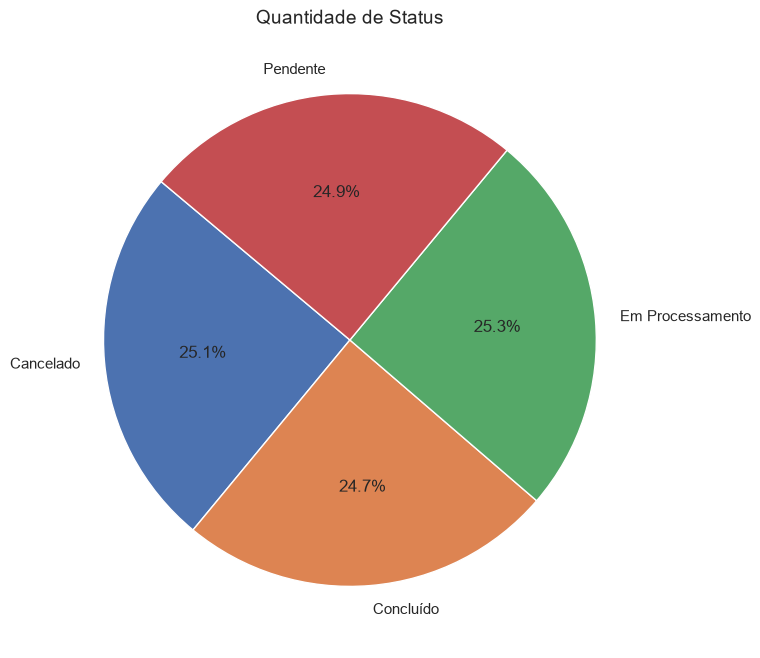

In [122]:
contagem_status = base_vendas.groupby("status_pedido").size().reset_index(name = "quantidade")

plt.figure(figsize = (12,8))
plt.pie(contagem_status["quantidade"], labels = contagem_status["status_pedido"], autopct = "%1.1f%%", startangle= 140)

plt.title("Quantidade de Status", fontsize = 14)
plt.tight_layout
plt.show()

In [123]:
base_vendas = base_vendas[base_vendas["status_pedido"].isin(["Concluído", "Em processamento"])]

In [124]:
def calcular_valor_total(valor):
    if valor["quantidade"] == 0:
        return 0
    else:
        return valor["preco_unitario"] * valor["quantidade"]
base_vendas["valor_total"] = base_vendas.apply(calcular_valor_total, axis = 1)

In [125]:
base_vendas = base_vendas[base_vendas["quantidade"] != 0]

base_vendas

,id_pedido,data_pedido,nome_cliente,produto,categoria,quantidade,preco_unitario,valor_total,metodo_pagamento,estado_cliente,status_pedido
3,ORD-17282,2025-03-14 22:58:00,Rodrigo Ferreira,Fone de Ouvido Bluetooth,Acessórios,5.0,200,1000.0,Crédito,BA,Concluído
8,ORD-13879,2025-01-04 01:41:00,Rafael Barbosa,Notebook Pro,Eletrônicos,1.0,4500,4500.0,Boleto bancário,SP,Concluído
16,ORD-15389,2024-03-11 00:24:00,Thiago Carvalho,Notebook Pro,Eletrônicos,2.0,4500,9000.0,Crédito,NÃO INFORMADO,Concluído
22,ORD-13059,2025-02-17 20:45:00,Lucas Mendes,Monitor 27 Polegadas,Eletrônicos,1.0,1200,1200.0,Boleto bancário,RJ,Concluído
25,ORD-14639,2024-07-23 20:52:00,Aline Pereira,Notebook Pro,Eletrônicos,3.0,4500,13500.0,Pix,MG,Concluído
...,...,...,...,...,...,...,...,...,...,...,...
10478,ORD-18666,2024-04-15 15:39:00,Patricia Ribeiro,Cadeira Ergonômica,Móveis,3.0,850,2550.0,Crédito,SC,Concluído
10480,ORD-13385,2024-08-03 08:33:00,Juliana Rocha,Cafeteira Expressa,Eletrodomésticos,1.0,400,400.0,Boleto bancário,RS,Concluído
10482,ORD-11184,2024-01-31 22:46:00,Camila Martins,Livro Data Science Guide,Livros,2.0,90,180.0,Crédito,PR,Concluído
10486,ORD-12433,2024-11-16 19:37:00,João Pedro Souza,Notebook Pro,Eletrônicos,1.0,4500,4500.0,Crédito,RJ,Concluído


In [126]:
base_vendas[base_vendas["valor_total"] == 0]

base_vendas.to_excel("base_vendas_limpa.xlsx", index = False)

In [127]:
base_vendas["data_pedido"] = pd.to_datetime(base_vendas["data_pedido"])
base_vendas.insert(2, "horário", base_vendas['data_pedido'].dt.time)
base_vendas["data_pedido"] = pd.to_datetime(base_vendas['data_pedido']).dt.date

base_vendas

,id_pedido,data_pedido,horário,nome_cliente,produto,categoria,quantidade,preco_unitario,valor_total,metodo_pagamento,estado_cliente,status_pedido
3,ORD-17282,2025-03-14,22:58:00,Rodrigo Ferreira,Fone de Ouvido Bluetooth,Acessórios,5.0,200,1000.0,Crédito,BA,Concluído
8,ORD-13879,2025-01-04,01:41:00,Rafael Barbosa,Notebook Pro,Eletrônicos,1.0,4500,4500.0,Boleto bancário,SP,Concluído
16,ORD-15389,2024-03-11,00:24:00,Thiago Carvalho,Notebook Pro,Eletrônicos,2.0,4500,9000.0,Crédito,NÃO INFORMADO,Concluído
22,ORD-13059,2025-02-17,20:45:00,Lucas Mendes,Monitor 27 Polegadas,Eletrônicos,1.0,1200,1200.0,Boleto bancário,RJ,Concluído
25,ORD-14639,2024-07-23,20:52:00,Aline Pereira,Notebook Pro,Eletrônicos,3.0,4500,13500.0,Pix,MG,Concluído
...,...,...,...,...,...,...,...,...,...,...,...,...
10478,ORD-18666,2024-04-15,15:39:00,Patricia Ribeiro,Cadeira Ergonômica,Móveis,3.0,850,2550.0,Crédito,SC,Concluído
10480,ORD-13385,2024-08-03,08:33:00,Juliana Rocha,Cafeteira Expressa,Eletrodomésticos,1.0,400,400.0,Boleto bancário,RS,Concluído
10482,ORD-11184,2024-01-31,22:46:00,Camila Martins,Livro Data Science Guide,Livros,2.0,90,180.0,Crédito,PR,Concluído
10486,ORD-12433,2024-11-16,19:37:00,João Pedro Souza,Notebook Pro,Eletrônicos,1.0,4500,4500.0,Crédito,RJ,Concluído


In [128]:
base_vendas['data_pedido'] = pd.to_datetime(base_vendas['data_pedido']).dt.strftime('%d/%m/%Y')

base_vendas['ano'] = base_vendas['data_pedido'].str.split('/').str[2]
base_vendas['mes'] = base_vendas['data_pedido'].str.split('/').str[1]
lista_extenso = {"01": "Janeiro",
                 "02": "Fevereiro",
                 "03": "Março",
                 "04": "Abril",
                 "05": "Maio",
                 "06": "Junho",
                 "07": "Julho",
                 "08": "Agosto",
                 "09": "Setembro",
                 "10": "Outubro",
                 "11": "Novembro",
                 "12": "Dezembro"}

base_vendas['mes'] = base_vendas['mes'].map(lista_extenso)

base_vendas

,id_pedido,data_pedido,horário,nome_cliente,produto,categoria,quantidade,preco_unitario,valor_total,metodo_pagamento,estado_cliente,status_pedido,ano,mes
3,ORD-17282,14/03/2025,22:58:00,Rodrigo Ferreira,Fone de Ouvido Bluetooth,Acessórios,5.0,200,1000.0,Crédito,BA,Concluído,2025,Março
8,ORD-13879,04/01/2025,01:41:00,Rafael Barbosa,Notebook Pro,Eletrônicos,1.0,4500,4500.0,Boleto bancário,SP,Concluído,2025,Janeiro
16,ORD-15389,11/03/2024,00:24:00,Thiago Carvalho,Notebook Pro,Eletrônicos,2.0,4500,9000.0,Crédito,NÃO INFORMADO,Concluído,2024,Março
22,ORD-13059,17/02/2025,20:45:00,Lucas Mendes,Monitor 27 Polegadas,Eletrônicos,1.0,1200,1200.0,Boleto bancário,RJ,Concluído,2025,Fevereiro
25,ORD-14639,23/07/2024,20:52:00,Aline Pereira,Notebook Pro,Eletrônicos,3.0,4500,13500.0,Pix,MG,Concluído,2024,Julho
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10478,ORD-18666,15/04/2024,15:39:00,Patricia Ribeiro,Cadeira Ergonômica,Móveis,3.0,850,2550.0,Crédito,SC,Concluído,2024,Abril
10480,ORD-13385,03/08/2024,08:33:00,Juliana Rocha,Cafeteira Expressa,Eletrodomésticos,1.0,400,400.0,Boleto bancário,RS,Concluído,2024,Agosto
10482,ORD-11184,31/01/2024,22:46:00,Camila Martins,Livro Data Science Guide,Livros,2.0,90,180.0,Crédito,PR,Concluído,2024,Janeiro
10486,ORD-12433,16/11/2024,19:37:00,João Pedro Souza,Notebook Pro,Eletrônicos,1.0,4500,4500.0,Crédito,RJ,Concluído,2024,Novembro


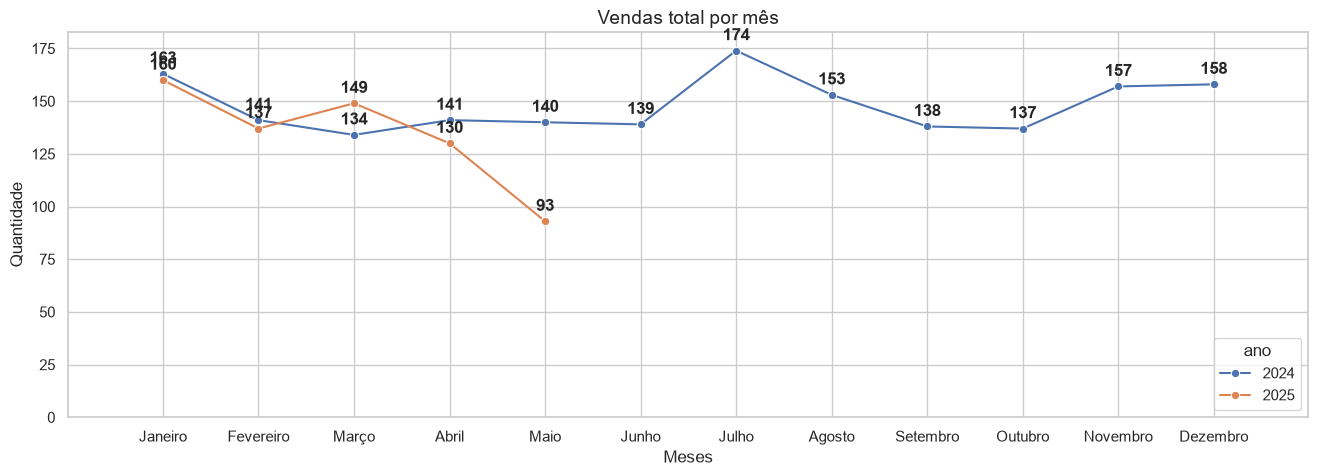

In [129]:
ordem_meses= ["Janeiro","Fevereiro","Março","Abril","Maio","Junho","Julho","Agosto","Setembro","Outubro","Novembro","Dezembro"]
base_vendas['mes'] = pd.Categorical(base_vendas['mes'], categories = ordem_meses, ordered=True)
tips = base_vendas.groupby(["mes", "ano"]).size().reset_index(name="quantidade")
sns.set_theme(style = "whitegrid")
plt.figure(figsize=(16,5))
ax = sns.lineplot(x="mes", y="quantidade", data = tips,hue = "ano", marker= "o")
sx = ax.bar(tips["mes"], tips["quantidade"], alpha = 0)
ax.bar_label(sx, padding=5,fontweight = "bold")
ax.set_title("Vendas total por mês", fontsize = 14)
ax.set_ylabel("Quantidade")
ax.set_xlabel("Meses")

plt.show()

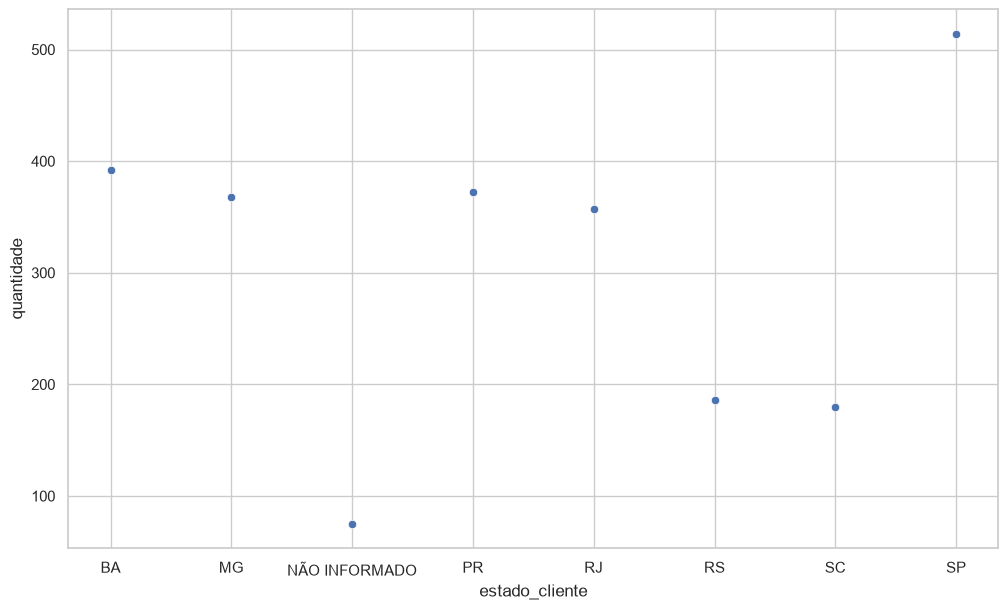

In [130]:
estado_contagem = base_vendas.groupby("estado_cliente").size().reset_index(name = "quantidade")
plt.figure(figsize=(12,7))
sns.set_theme(style="whitegrid")
ax = sns.scatterplot(x="estado_cliente", y="quantidade", data = estado_contagem)